# Random Forest come sviluppo del Decision Tree: introduzione al modello e applicazione alla predizione del degrado gomme in Formula 1

Notebook di analisi della tesi triennale. Si vuole capire se le **velocità in qualifica** (proxy dell'assetto aerodinamico) permettono di prevedere se uno stint di gara ha **alto o basso degrado** delle gomme.

**Schema del notebook**
1. Caricamento, filtri e costruzione di feature e target
2. Impostazione della cross validation
3. Modelli: Logistic Regression, kNN, Decision Tree, Random Forest
4. Confronto, test sul 2025, baseline e permutation test

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, cross_val_predict, cross_val_score, permutation_test_score, LeaveOneGroupOut
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay

## 1. Caricamento dei dati e analisi

Il file `f1_dataset.csv` contiene una riga per stint, con il degrado stimato (`Degrado`, in s/giro), il numero di giri, il circuito, l'anno, la mescola e le velocità di qualifica `SpeedST`, `SpeedI1`, `SpeedI2` (traguardo e due intermedi).

In [2]:
# Carico il dataset (una riga per stint). Il file va messo nella cartella del notebook
# o in data/ (in quel caso usare 'data/f1_dataset.csv').
df = pd.read_csv('f1_dataset.csv')

df.head()

,Anno,Circuito,Pilota,Team,Stint,SpeedST,SpeedI1,SpeedI2,SpeedMin,FullThrottle,...,FreshTyre,GiroInizio,TrackTemp_Q,Rainfall_Q,TrackTemp_R,Rainfall_R,AirTemp_R,Humidity_R,WindSpeed_R,Degrado
0,2022,Miami Grand Prix,VER,Red Bull Racing,1.0,334.0,223.0,192.0,67.0,0.557276,...,1,2.0,51.20875,0,42.819753,1,30.617284,58.858025,2.267284,-0.001699
1,2022,Miami Grand Prix,VER,Red Bull Racing,2.0,334.0,223.0,192.0,67.0,0.557276,...,1,28.0,51.20875,0,42.819753,1,30.617284,58.858025,2.267284,0.009186
2,2022,Miami Grand Prix,GAS,AlphaTauri,1.0,326.0,221.0,191.0,65.0,0.571429,...,1,2.0,51.20875,0,42.819753,1,30.617284,58.858025,2.267284,-0.007439
3,2022,Miami Grand Prix,GAS,AlphaTauri,2.0,326.0,221.0,191.0,65.0,0.571429,...,1,18.0,51.20875,0,42.819753,1,30.617284,58.858025,2.267284,0.016970
4,2022,Miami Grand Prix,PER,Red Bull Racing,1.0,332.0,223.0,192.0,64.0,0.582822,...,1,2.0,51.20875,0,42.819753,1,30.617284,58.858025,2.267284,0.025519


Filtri sui dati. 

Dal dataset iniziale tengo solo gli stint (periodo di gara o di prova in cui un pilota guida in pista usando la stessa gomma) con almeno 8 giri, per avere una stima del degrado abbastanza stabile. Escludo le gare con pioggia (Rainfall_R), perché il degrado in bagnato ha dinamiche diverse. Scarto gli stint con |Degrado| >= 0.5 s/giro, valori che considero anomali (outlier). Infine tengo solo i gruppi (Circuito, Anno, Compound) con almeno 4 stint, per non avere gruppi troppo piccoli.

In [3]:
# Filtri di qualità sui singoli stint:
#  - almeno 8 giri, per una stima del degrado stabile
#  - niente gare con pioggia (Rainfall_R deve essere di tipo bool)
#  - |Degrado| < 0.5 s/giro, per scartare gli outlier
df = df[(df["N_giri"] >= 8) & (~df["Rainfall_R"]) & (df["Degrado"].abs() < 0.5)]

# Tengo solo i gruppi (circuito, anno, mescola) con almeno 4 stint,
# per non avere gruppi troppo piccoli
n_gruppo = df.groupby(["Circuito", "Anno", "Compound"])["Degrado"].transform("count")
df = df[n_gruppo >= 4]

Rendo le velocità **relative**: per ogni gara sottraggo la mediana delle velocità di quella gara. Così la feature indica se un pilota è più veloce o più lento del gruppo, indipendentemente dal circuito. La mediana è calcolata con un valore per pilota, per non pesare di più chi ha fatto più stint.

In [4]:
speed_cols = ["SpeedST", "SpeedI1", "SpeedI2"]   # velocità assolute di qualifica
gara_id = ["Circuito", "Anno"]                   # una gara = circuito + anno

# Una riga per pilota e gara, così ogni pilota pesa una sola volta nella mediana
per_pilota = df.drop_duplicates(gara_id + ["Pilota"])

# Mediana delle velocità per gara, riunita al dataset con il suffisso _med
med = per_pilota.groupby(gara_id)[speed_cols].median().add_suffix("_med")
df = df.join(med, on=gara_id)

# Velocità relativa = velocità del pilota - mediana della gara
for c in speed_cols:
    df[c + "_rel"] = df[c] - df[c + "_med"]

# Elimino le colonne assolute e di appoggio: restano solo le feature *_rel
df = df.drop(columns=speed_cols + [c + "_med" for c in speed_cols])

In [5]:
# Split temporale: training sulle stagioni 2022-2024, test sul 2025
df_train = df[df['Anno'].isin([2022, 2023, 2024])].copy()
df_test = df[df['Anno'] == 2025].copy()

print("Train:", df_train.shape)
print("Test:", df_test.shape)

Train: (1938, 23)
Test: (634, 23)


Per ogni coppia (Circuito, Compound) calcolo la mediana del Degrado sui soli anni di training. Uno stint è `HighDeg = 1` se il suo degrado supera la mediana della sua coppia, altrimenti 0. La soglia è calcolata solo sul training e poi applicata al test, per evitare data leakage. Includo anche `Compound` nella chiave perché la domanda è: "a parità di circuito e mescola, dall'assetto posso predire il degrado?". Per costruzione le due classi sono quasi bilanciate.

In [6]:
# Chiave di raggruppamento per la soglia del degrado
chiave = ['Circuito', 'Compound']

# Mediana del degrado per (circuito, mescola), calcolata SOLO sul training
soglia = df_train.groupby(chiave)['Degrado'].median().rename('soglia')

df_train = df_train.join(soglia, on=chiave)
df_test = df_test.join(soglia, on=chiave)

# Nel test tengo solo le combinazioni (circuito, mescola) viste nel training
df_test = df_test.dropna(subset=['soglia']).copy()

# Target binario: 1 = degrado sopra la mediana (alto), 0 = sotto (basso)
df_train['HighDeg'] = (df_train['Degrado'] > df_train['soglia']).astype(int)
df_test['HighDeg'] = (df_test['Degrado'] > df_test['soglia']).astype(int)

# Controllo del bilanciamento delle classi
print(df_train['HighDeg'].value_counts())
print(df_test['HighDeg'].value_counts())

HighDeg
0    981
1    957
Name: count, dtype: int64
HighDeg
0    336
1    275
Name: count, dtype: int64


In [7]:
# Valori mancanti per colonna (verranno imputati con la mediana nella pipeline)
df_train.isnull().sum()

Anno                0
Circuito            0
Pilota              0
Team                0
Stint               0
SpeedMin            6
FullThrottle        6
Compound            0
TyreLife_inizio     0
N_giri              0
FreshTyre           0
GiroInizio          0
TrackTemp_Q         0
Rainfall_Q          0
TrackTemp_R         0
Rainfall_R          0
AirTemp_R           0
Humidity_R          0
WindSpeed_R         0
Degrado             0
SpeedST_rel         8
SpeedI1_rel        14
SpeedI2_rel         6
soglia              0
HighDeg             0
dtype: int64

In [8]:
# Feature usate dai modelli
cols = ["SpeedST_rel", "SpeedI1_rel", "SpeedI2_rel"]

X = df_train[cols]        # feature di training
X_test = df_test[cols]    # feature di test

y = df_train["HighDeg"]   # target di training
y_test = df_test["HighDeg"]  # target di test

In [9]:
# Controllo rapido di feature e target
X.head()
y.head()

42    1
43    0
44    0
45    1
46    0
Name: HighDeg, dtype: int32

In [10]:
# Statistiche descrittive delle feature (anche in formato LaTeX per la tesi)
stat = df_train[cols].describe().loc[["mean", "std", "min", "max"]].round(2)
print(stat)
print(stat.to_latex())

      SpeedST_rel  SpeedI1_rel  SpeedI2_rel
mean        -0.21        -0.23        -0.43
std          4.52         5.25         6.97
min        -30.00       -47.50      -186.00
max         17.00        19.50        13.00
\begin{tabular}{lrrr}
\toprule
 & SpeedST_rel & SpeedI1_rel & SpeedI2_rel \\
\midrule
mean & -0.210000 & -0.230000 & -0.430000 \\
std & 4.520000 & 5.250000 & 6.970000 \\
min & -30.000000 & -47.500000 & -186.000000 \\
max & 17.000000 & 19.500000 & 13.000000 \\
\bottomrule
\end{tabular}



In [11]:
# Controllo di valori molto bassi (< -50 km/h), possibili anomalie di misura
print((df_train[cols] < -50).sum())
print(df_train[df_train["SpeedI2_rel"] < -50][["Circuito", "Anno", "Pilota", "SpeedI2_rel"]])

SpeedST_rel    0
SpeedI1_rel    0
SpeedI2_rel    2
dtype: int64
                      Circuito  Anno Pilota  SpeedI2_rel
1435  Saudi Arabian Grand Prix  2023    SAR       -186.0
1436  Saudi Arabian Grand Prix  2023    SAR       -186.0


**Commento.** I valori molto bassi di `SpeedI2_rel` (minimo circa −186 km/h) riguardano soli due record consecutivi dello stesso pilota nel Gran Premio dell'Arabia Saudita 2023: sono un caso estremo di misura e il loro effetto sul modello è trascurabile. La distribuzione ha una coda verso i valori bassi (minimi molto più lontani dallo zero dei massimi).

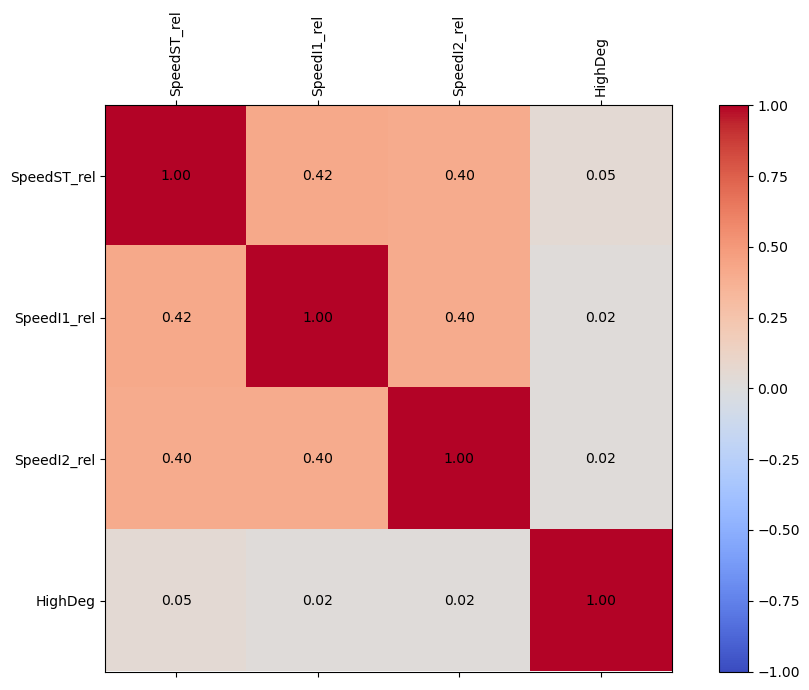

In [12]:
# Heatmap delle correlazioni (feature + target)
# 1. Unisco feature e target in un unico DataFrame
df_corr = X.copy()
df_corr['HighDeg'] = y

# 2. Matrice di correlazione tra feature e target
corr_matrix = df_corr.corr()

# 3. Heatmap delle correlazioni
fig, ax = plt.subplots(figsize=(10,7))
cax = ax.matshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)

fig.colorbar(cax)

ticks = range(len(corr_matrix.columns))
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.set_xticklabels(corr_matrix.columns, rotation=90)
ax.set_yticklabels(corr_matrix.columns)

# Mette i valori dentro ogni casella
for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        valore = corr_matrix.iloc[i, j]
        ax.text(j, i, f"{valore:.2f}", 
                ha='center', va='center', fontsize=10)

plt.tight_layout()
plt.show()

**Commento alla heatmap.** Mostra la correlazione tra le tre velocità relative e il target `HighDeg`. Le correlazioni *con il target* sono quelle che contano: se sono vicine a zero, nessuna velocità da sola è associata al livello di degrado. Le correlazioni *tra le feature* indicano quanta informazione è ridondante (le velocità di settori diversi della stessa vettura tendono a muoversi insieme).

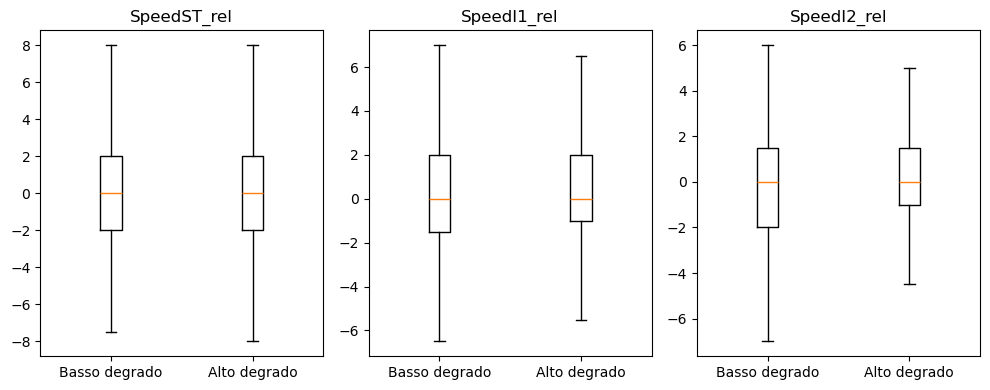

In [13]:
# Distribuzione di ogni feature nelle due classi (outlier non mostrati).
# Se le scatole si sovrappongono molto, la feature separa poco le classi.
fig, axs = plt.subplots(1, 3, figsize=(10, 4))

for ax, c in zip(axs, cols):
    ax.boxplot([X.loc[y == 0, c].dropna(), X.loc[y == 1, c].dropna()], showfliers=False)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Basso degrado", "Alto degrado"])
    ax.set_title(c)

plt.tight_layout()
plt.show()

**Commento ai boxplot.** Per `SpeedST_rel` e `SpeedI1_rel` le mediane dei due gruppi (basso e alto degrado) coincidono e le dispersioni sono quasi identiche; `SpeedI2_rel` ha una dispersione leggermente minore nel gruppo ad alto degrado. Le distribuzioni si sovrappongono in gran parte: **nessuna velocità, da sola, separa i due livelli di degrado**. Questo anticipa già che il problema è difficile.

In [14]:
# Correlazione tra le feature: serve a vedere se sono ridondanti
print(df[["SpeedST_rel", "SpeedI1_rel", "SpeedI2_rel"]].corr())

             SpeedST_rel  SpeedI1_rel  SpeedI2_rel
SpeedST_rel     1.000000     0.381859     0.391759
SpeedI1_rel     0.381859     1.000000     0.399617
SpeedI2_rel     0.391759     0.399617     1.000000


## 2. Cross validation

Uso `LeaveOneGroupOut` con l'anno come gruppo: a ogni fold si addestra su due stagioni e si valuta sulla terza. In questo modo la validazione rispetta la divisione temporale e non mescola stint della stessa gara tra train e validation. La metrica è la balanced accuracy.

In [15]:
groups = df_train["Anno"]   # ogni anno è un gruppo (fold)
cv = LeaveOneGroupOut()     # 3 fold: addestro su 2 anni, valido sul terzo

In [16]:
# Regola dell'errore standard ("one standard error rule").
# Tra tutte le combinazioni di iperparametri con score entro 1 deviazione standard
# dal migliore, scelgo la più SEMPLICE (minore rischio di overfitting).
# `semplicita` è una funzione che dà un punteggio di semplicità ai parametri:
# più è alto, più il modello è semplice.
def one_std_rule(semplicita):
    def refit(res):
        m, s = res["mean_test_score"], res["std_test_score"]
        best = m.argmax()                           # combinazione con score migliore
        ok = np.where(m >= m[best] - s[best])[0]    # quelle entro 1 std dal migliore
        return max(ok, key=lambda i: semplicita(res["params"][i]))  # la più semplice
    return refit

# Per ogni modello, definisco cosa significa "più semplice":
# - Logistica: C piccolo = più regolarizzata
rule_logistic = one_std_rule(lambda p: -p["model__C"])
# - kNN: k grande = confine più liscio
rule_knn      = one_std_rule(lambda p: p["model__n_neighbors"])
# - Albero: poco profondo, poi foglie grandi (None = profondità illimitata -> 999)
rule_tree     = one_std_rule(lambda p: (-(p["model__max_depth"] or 999), p["model__min_samples_leaf"]))
# - Foresta: come l'albero, e a parità pochi alberi
rule_forest   = one_std_rule(lambda p: (-(p["model__max_depth"] or 999), p["model__min_samples_leaf"], -p["model__n_estimators"]))

# Score medio in CV della combinazione scelta dal refit
def best_score(g):
    return g.cv_results_["mean_test_score"][g.best_index_]

## 3. Classificazione tramite minimizzazione del rischio empirico con loss logistica

Il parametro `C` è l'inverso della regolarizzazione: valori piccoli = modello più vincolato.

In [17]:
# Pipeline per la gestione del preprocessing e del modello LogisticRegression
# Previene il data leakage applicando le trasformazioni in sequenza
logistic_pipeline = Pipeline([
    # 1. Gestione NaN: sostituisce i valori mancanti con la mediana della colonna
    ("imputer", SimpleImputer(strategy="median")),
    # 2. Standardizzazione: porta i dati a media 0 e varianza 1 (fondamentale per i modelli lineari)
    ("scaler", StandardScaler()),
    # 3. Modello: Logistic Regression
    ("model", LogisticRegression(max_iter=5000))
])

In [18]:
# Valori di C da testare (scala logaritmica)

logistic_param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]
}

# Routine di grid search tramite cross validation del parametro ottimale

logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    cv=cv,
    scoring="balanced_accuracy",
    refit=rule_logistic,
    return_train_score=True
)

# Grid search in CV; `groups` indica a LeaveOneGroupOut l'anno di ogni riga
logistic_grid.fit(X, y, groups=groups)

print("Migliori parametri LogisticRegression:")
print(logistic_grid.best_params_)

Migliori parametri LogisticRegression:
{'model__C': 0.01}


mean=0.4971657, std=0.01357250, params={'model__C': 0.001}
mean=0.5123090, std=0.01513083, params={'model__C': 0.01}
mean=0.5112246, std=0.01808835, params={'model__C': 0.1}
mean=0.5107069, std=0.01721294, params={'model__C': 1.0}
mean=0.5107069, std=0.01721294, params={'model__C': 10.0}
mean=0.5107069, std=0.01721294, params={'model__C': 100.0}
mean=0.5107069, std=0.01721294, params={'model__C': 1000.0}
mean=0.5107069, std=0.01721294, params={'model__C': 10000.0}


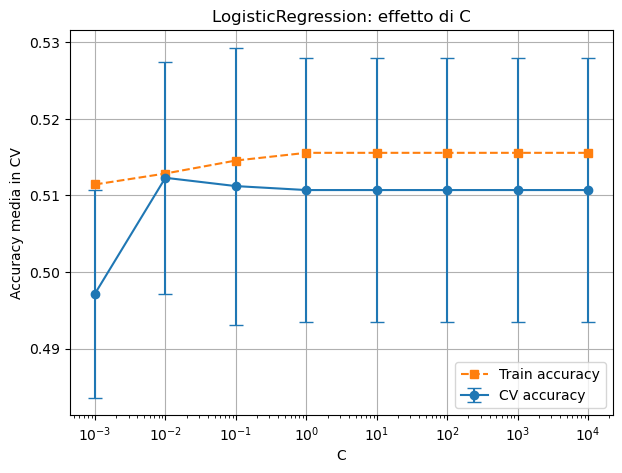

In [19]:
# Stampo score medio e deviazione standard per ogni valore di C
logistic_results = logistic_grid.cv_results_

for mean, std, params in zip(
    logistic_results["mean_test_score"],
    logistic_results["std_test_score"],
    logistic_results["params"]
):
    print(f"mean={mean:.7f}, std={std:.8f}, params={params}")

C = logistic_param_grid["model__C"]
# Grafico: score in CV (con barre d'errore) e score di train al variare di C.
# Un grande distacco train/CV indica overfitting.
plt.figure(figsize=(7, 5))
plt.errorbar(C, logistic_results["mean_test_score"], yerr=logistic_results["std_test_score"], marker="o", capsize=5, label="CV accuracy")
plt.plot(C, logistic_results["mean_train_score"], marker="s", linestyle="--", label="Train accuracy")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Accuracy media in CV")
plt.title("LogisticRegression: effetto di C")
plt.legend()
plt.grid(True)
plt.show()

**Commento al grafico (Regressione Logistica).** Al variare di `C` (scala logaritmica) sia lo score in CV sia quello di train restano vicini al 50%: il modello lineare non riesce a ricavare nulla di utile dalle tre velocità. Per questo la regola dell'errore standard sceglie un valore piccolo di `C` (modello molto regolarizzato, `C = 0.01` nella tesi), con balanced accuracy in CV di circa 0.512.

## 4. k-NN

Il parametro `k` controlla la complessità: `k` piccolo = confine di decisione frastagliato, `k` grande = confine più liscio.

In [20]:
# Pipeline per la gestione del preprocessing e del modello kNN
# Previene il data leakage applicando le trasformazioni in sequenza
knn_pipeline = Pipeline([
    # 1. Gestione NaN: sostituisce i valori mancanti con la mediana della colonna
    ("imputer", SimpleImputer(strategy="median")),
    # 2. Standardizzazione: porta i dati a media 0 e varianza 1 (fondamentale per kNN, che usa le distanze)
    ("scaler", StandardScaler()),
    # 3. Modello: k-Nearest Neighbors
    ("model", KNeighborsClassifier())
])

In [21]:
# Valori di k (numero di vicini) da testare

knn_param_grid = {
    "model__n_neighbors": [1, 3, 5, 10, 15, 20, 30, 50]
}

# Routine di grid search tramite cross validation del parametro ottimale

knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=cv,
    scoring="balanced_accuracy",
    refit=rule_knn,
    return_train_score=True
)

# Grid search in CV; `groups` indica l'anno di ogni riga

knn_grid.fit(X,y, groups=groups)

print("Migliori parametri k-Nearest Neighbors:")
print(knn_grid.best_params_)

Migliori parametri k-Nearest Neighbors:
{'model__n_neighbors': 30}


mean=0.5155909, std=0.01441764, params={'model__n_neighbors': 1}
mean=0.4972755, std=0.00170752, params={'model__n_neighbors': 3}
mean=0.4905440, std=0.00242663, params={'model__n_neighbors': 5}
mean=0.5017157, std=0.00126196, params={'model__n_neighbors': 10}
mean=0.5007776, std=0.00930166, params={'model__n_neighbors': 15}
mean=0.5086928, std=0.01018702, params={'model__n_neighbors': 20}
mean=0.5066920, std=0.00936508, params={'model__n_neighbors': 30}
mean=0.4977410, std=0.02290730, params={'model__n_neighbors': 50}


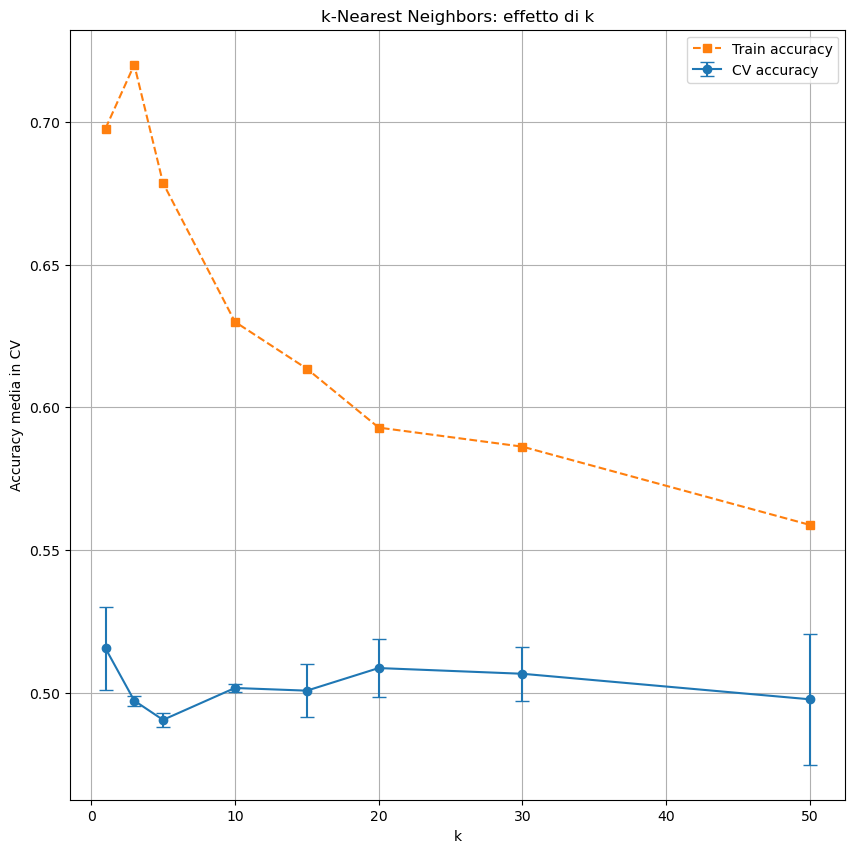

In [22]:
# Stampo score medio e deviazione standard per ogni valore di k
knn_results = knn_grid.cv_results_

for mean, std, params in zip(
    knn_results["mean_test_score"],
    knn_results["std_test_score"],
    knn_results["params"]
):
    print(f"mean={mean:.7f}, std={std:.8f}, params={params}")

# Grafico: score in CV e di train al variare di k
k = knn_param_grid["model__n_neighbors"]
plt.figure(figsize=(10, 10))
plt.errorbar(k, knn_results["mean_test_score"], yerr=knn_results["std_test_score"], marker="o", capsize=5, label="CV accuracy")
plt.plot(k, knn_results["mean_train_score"], marker="s", linestyle="--", label="Train accuracy")
plt.xlabel("k")
plt.ylabel("Accuracy media in CV")
plt.title("k-Nearest Neighbors: effetto di k")
plt.legend()
plt.grid(True)
plt.show()

**Commento al grafico (kNN).** Con `k` piccolo il modello memorizza il training (score di train molto alto) ma in CV è vicino al caso; aumentando `k` le due curve si avvicinano attorno al 50%. La regola dell'errore standard sceglie un `k` grande (30 nella tesi), cioè il confine più liscio, con balanced accuracy in CV di circa 0.507.

## 5. Decision Tree

I parametri `max_depth` e `min_samples_leaf` limitano la crescita dell'albero. Un albero profondo tende all'overfitting (train accuracy alta, CV bassa).

**Limiti del singolo albero.** L'errore atteso di generalizzazione si scompone in

$$\text{Errore atteso} = \text{Bias}^2 + \text{Varianza} + \text{Rumore irriducibile}$$

Un albero profondo e senza vincoli sulle foglie ha **bias basso** (si adatta quasi perfettamente ai dati di addestramento) ma **varianza alta**: la sua struttura dipende molto dalla composizione del training set, e poche osservazioni in più o in meno possono cambiare i primi split e le variabili scelte. Superata la profondità ottimale l'albero tende a memorizzare il rumore: l'accuratezza in training continua a crescere, quella su dati nuovi no. Per questo `max_depth` e `min_samples_leaf` sono limitati nella grid search.

In [23]:
# Pipeline per la gestione del preprocessing e del modello DecisionTree
# Previene il data leakage applicando le trasformazioni in sequenza
tree_pipeline = Pipeline([
    # 1. Gestione NaN: sostituisce i valori mancanti con la mediana della colonna
    ("imputer", SimpleImputer(strategy="median")),
    # 2. Standardizzazione: porta i dati a media 0 e varianza 1 (non necessaria per i modelli ad albero,
    #    la tengo per avere la stessa pipeline per tutti i modelli)
    ("scaler", StandardScaler()),
    # 3. Modello: Decision Tree
    ("model", DecisionTreeClassifier())
])

In [24]:
# Griglia: profondità massima (None = illimitata) e minimo di campioni per foglia
tree_param_grid = {
    "model__max_depth": [2, 3, 5, 10, 15, 20, None],
    "model__min_samples_leaf": [1, 2, 5, 10]
}

tree_grid = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=tree_param_grid,
    cv=cv,
    scoring="balanced_accuracy",
    refit=rule_tree,
    return_train_score=True
)

tree_grid.fit(X, y, groups=groups)

print("Migliori parametri DecisionTreeClassifier:")
print(tree_grid.best_params_)
print("Miglior balanced accuracy media in CV:", best_score(tree_grid))

Migliori parametri DecisionTreeClassifier:
{'model__max_depth': 3, 'model__min_samples_leaf': 5}
Miglior balanced accuracy media in CV: 0.52157227293316


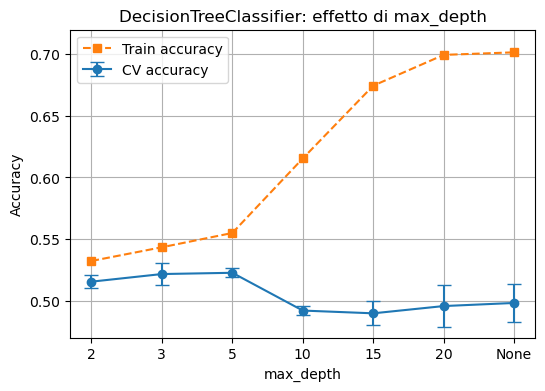

In [25]:
# Grafico dell'effetto di max_depth, tenendo fisso min_samples_leaf al valore scelto.
# Per ogni profondità cerco la riga corrispondente in cv_results_.
tree_results = tree_grid.cv_results_

depths = tree_param_grid["model__max_depth"]
depth_labels = [str(d) for d in depths]

means_test = []
means_train = []
stds = []

for depth in depths:
    for p, mean_test, mean_train, std in zip(
        tree_results["params"],
        tree_results["mean_test_score"],
        tree_results["mean_train_score"],
        tree_results["std_test_score"],
    ):
        if p["model__max_depth"] == depth and p["model__min_samples_leaf"] == tree_grid.best_params_["model__min_samples_leaf"]:
            means_test.append(mean_test)
            means_train.append(mean_train)
            stds.append(std)
            break

plt.figure(figsize=(6, 4))
plt.errorbar(depth_labels, means_test, yerr=stds, marker="o", capsize=5, label="CV accuracy")
plt.plot(depth_labels, means_train, marker="s", linestyle="--", label="Train accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.ylim(0.47, 0.72)    
plt.title("DecisionTreeClassifier: effetto di max_depth")
plt.legend()
plt.grid(True)
plt.show()

**Commento al grafico (Decision Tree).** Aumentando `max_depth` l'accuratezza sul training cresce (da circa il 53% al 70%), mentre quella in CV resta attorno al 52% fino a profondità 5 e poi scende sotto il 50%. È il tipico comportamento di **overfitting**: l'albero memorizza il campione di addestramento e perde capacità di generalizzare. Per questo la grid search sceglie un albero poco profondo (profondità 3, foglia minima 5 nella tesi), con balanced accuracy in CV di circa 0.522.

## 6. Random Forest

### Dal Decision Tree alla Random Forest

**Bagging.** Per ridurre l'instabilità dell'albero si addestrano $B$ alberi sugli stessi dati visti in versioni diverse: ogni albero è allenato su un campione *bootstrap* (N osservazioni estratte con reinserimento dal training set) e le previsioni si combinano con il voto di maggioranza. Se i $B$ alberi avessero varianza $\sigma^2$ e correlazione media $\rho$ tra le coppie, la varianza della previsione aggregata sarebbe

$$\text{Var}(\hat f_{bag}(x)) = \rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$$

Il secondo termine diminuisce aumentando $B$; il primo, $\rho\sigma^2$, resta e rappresenta un limite inferiore alla varianza che il solo bagging non elimina. L'idea alla base del voto di maggioranza è il teorema della giuria di Condorcet: se i classificatori sono indipendenti e ciascuno ha probabilità > 0.5 di indovinare, il voto di maggioranza è corretto con probabilità che tende a 1 al crescere di $B$. In pratica gli alberi non sono mai indipendenti, perché derivano dallo stesso dataset.

**Random Forest (Breiman, 2001).** Per ridurre $\rho$, ad ogni nodo di ogni albero la ricerca dello split migliore è limitata a un sottoinsieme casuale di $m \le p$ variabili (di solito $m = \lfloor\sqrt{p}\rfloor$ in classificazione), invece di considerarle tutte come nel bagging. Gli alberi diventano più diversi tra loro e la correlazione scende.

**Perché funziona (e quando no).** L'errore di generalizzazione della foresta soddisfa

$$PE^* \le \frac{\rho\,(1-s^2)}{s^2}$$

dove $s$ è la *forza* della foresta (margine medio) e $\rho$ la correlazione tra gli alberi. Per migliorare bisogna ridurre $\rho$ senza ridurre $s$: un $m$ troppo piccolo rende gli alberi diversi ma meno accurati. Il punto fondamentale è che serve $s > 0$: se i singoli alberi sono poco migliori del caso, $s$ è vicino a zero e il limite superiore diventa inutile. **La foresta riduce la varianza, ma non può creare un segnale che nei dati non c'è.**

**Interpretabilità.** A differenza del singolo albero, la foresta è una "scatola chiusa". L'importanza delle variabili (permutazione sui dati out-of-bag) permette di capire quali feature contano, ma ha senso solo se il modello supera il caso.

In sintesi: il Decision Tree è facile da interpretare ma instabile (varianza alta); la Random Forest costa in interpretabilità ma stabilizza le previsioni, a patto che negli alberi ci sia un segnale di base.

In [26]:
# Pipeline per la gestione del preprocessing e del modello RandomForest
# Previene il data leakage applicando le trasformazioni in sequenza
forest_pipeline = Pipeline([
    # 1. Gestione NaN: sostituisce i valori mancanti con la mediana della colonna
    ("imputer", SimpleImputer(strategy="median")),
    # 2. Standardizzazione: porta i dati a media 0 e varianza 1 (non necessaria per i modelli ad albero,
    #    la tengo per avere la stessa pipeline per tutti i modelli)
    ("scaler", StandardScaler()),
    # 3. Modello: Random Forest
    # random_state controlla la costruzione interna degli alberi altrimenti cambia ogni run
    ("model", RandomForestClassifier(random_state=42))
])

In [27]:
# Griglia: numero di alberi, profondità massima e minimo di campioni per foglia.
# random_state fissato nella pipeline per avere risultati riproducibili.
forest_param_grid = {
    "model__n_estimators": [10, 50, 100, 150,200, 300],
    "model__max_depth": [5, 10, 15, 20, None],
    "model__min_samples_leaf": [1, 5, 10]
}

forest_grid = GridSearchCV(
    estimator=forest_pipeline,
    param_grid=forest_param_grid,
    cv=cv,
    scoring="balanced_accuracy",
    refit=rule_forest,
    return_train_score=True
)

forest_grid.fit(X, y, groups=groups)

print("Migliori parametri RandomForestClassifier:")
print(forest_grid.best_params_)
print("Miglior balanced accuracy media in CV:", best_score(forest_grid))

Migliori parametri RandomForestClassifier:
{'model__max_depth': 5, 'model__min_samples_leaf': 5, 'model__n_estimators': 150}
Miglior balanced accuracy media in CV: 0.5145636889991728


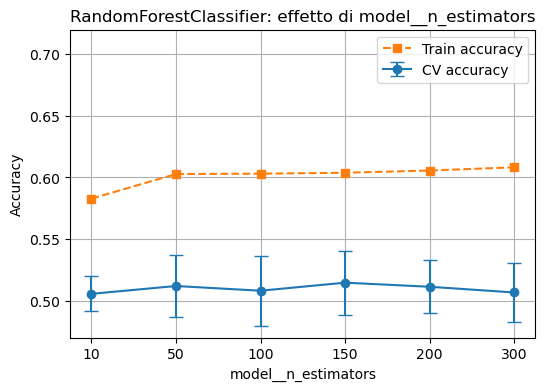

In [28]:
# Grafico dell'effetto del numero di alberi, tenendo fissi max_depth e min_samples_leaf
# ai valori scelti. (La variabile `depths` contiene qui i valori di n_estimators.)
forest_results = forest_grid.cv_results_

depths = forest_param_grid["model__n_estimators"]
depth_labels = [str(d) for d in depths]

means_test = []
means_train = []
stds = []

for depth in depths:
    for p, mean_test, mean_train, std in zip(
        forest_results["params"],
        forest_results["mean_test_score"],
        forest_results["mean_train_score"],
        forest_results["std_test_score"],
    ):
        if p["model__n_estimators"] == depth and p["model__max_depth"] == forest_grid.best_params_["model__max_depth"] and p["model__min_samples_leaf"] == forest_grid.best_params_["model__min_samples_leaf"]:
            means_test.append(mean_test)
            means_train.append(mean_train)
            stds.append(std)
            break

plt.figure(figsize=(6, 4))
plt.errorbar(depth_labels, means_test, yerr=stds, marker="o", capsize=5, label="CV accuracy")
plt.plot(depth_labels, means_train, marker="s", linestyle="--", label="Train accuracy")
plt.xlabel("model__n_estimators")
plt.ylabel("Accuracy")
plt.ylim(0.47, 0.72)
plt.title("RandomForestClassifier: effetto di model__n_estimators")
plt.legend()
plt.grid(True)
plt.show()

**Commento al grafico (Random Forest).** Aumentare il numero di alberi non porta nessun beneficio: la CV oscilla tra il 50.5% e il 51.5%, con barre d'errore che non permettono di distinguerla dalla soglia del caso (0.5). È coerente con la teoria: l'aggregazione di alberi non può estrarre un segnale informativo assente nei dati. La balanced accuracy in CV è circa 0.515, poco sotto quella del singolo Decision Tree.

## 7. Riassunto

Confronto dei quattro modelli sulla balanced accuracy media in CV e scelta del migliore.

In [29]:
# Riepilogo: iperparametri scelti e balanced accuracy media in CV per ogni modello
print("\nLogisticRegression")
print("best params:", logistic_grid.best_params_)
print("best CV balanced accuracy:", best_score(logistic_grid))

print("\nkNNeighborsClassifer")
print("best params:", knn_grid.best_params_)
print("best CV balanced accuracy:", best_score(knn_grid))

print("\nDecisionTreeClassifier")
print("best params:", tree_grid.best_params_)
print("best CV balanced accuracy:", best_score(tree_grid))

print("\nRandomForestClassifier")
print("best params:", forest_grid.best_params_)
print("best CV balanced accuracy:", best_score(forest_grid))

model_names = ["LogisticRegression", "kNNeighborsClassifer", "DecisionTree", "RandomForestClassifier"]
best_cv_scores = [best_score(logistic_grid), best_score(knn_grid), best_score(tree_grid), best_score(forest_grid)]


LogisticRegression
best params: {'model__C': 0.01}
best CV balanced accuracy: 0.5123090462404979

kNNeighborsClassifer
best params: {'model__n_neighbors': 30}
best CV balanced accuracy: 0.5066920467525305

DecisionTreeClassifier
best params: {'model__max_depth': 3, 'model__min_samples_leaf': 5}
best CV balanced accuracy: 0.52157227293316

RandomForestClassifier
best params: {'model__max_depth': 5, 'model__min_samples_leaf': 5, 'model__n_estimators': 150}
best CV balanced accuracy: 0.5145636889991728


**Commento al confronto.** Nessun modello migliora nettamente la baseline: in CV i valori restano tra circa 0.507 e 0.522, cioè al massimo due punti sopra il caso, e le differenze tra gli algoritmi sono ancora più piccole. La Random Forest non supera il Decision Tree (0.515 contro 0.522): la foresta riduce la varianza dei singoli alberi, ma l'errore resta vincolato alla forza $s$ (Sezione 6), e qui $s$ è prossima a zero. Si sceglie quindi il Decision Tree, anche se di poco. Non si riporta l'importanza delle variabili: su un modello che non supera il caso non avrebbe un'interpretazione affidabile.

In [30]:
# Scelgo il modello con la migliore balanced accuracy in CV.
# `best_estimator_` è la pipeline già rifittata sull'intero training set.
best_index = best_cv_scores.index(max(best_cv_scores))
final_model_name = model_names[best_index]
final_model = [logistic_grid, knn_grid, tree_grid, forest_grid][best_index].best_estimator_

print("Modello finale scelto:", final_model_name)

Modello finale scelto: DecisionTree


## 8. Test

Il modello scelto viene valutato **una sola volta** sulla stagione 2025, mai usata per addestrare né per scegliere gli iperparametri.

In [31]:
# Predizioni sul test 2025 e balanced accuracy
y_test_pred = final_model.predict(X_test)
test_acc = balanced_accuracy_score(y_test,y_test_pred)

print("Modello finale:", final_model_name)
print("Test accuracy:", test_acc)

Modello finale: DecisionTree
Test accuracy: 0.46228896103896105


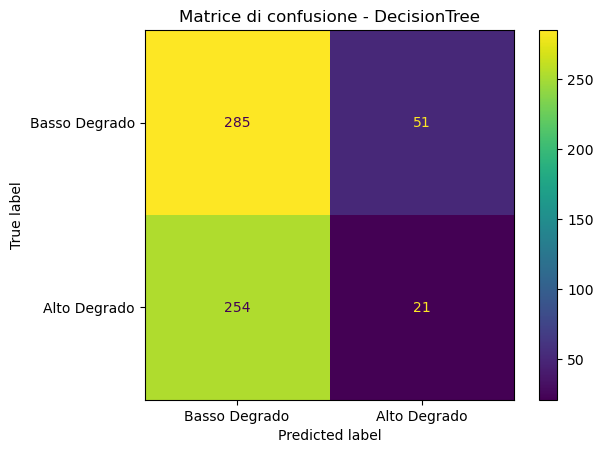

Balanced accuracy dalla matrice di confusione: 0.46228896103896105


In [32]:
# Matrice di confusione sul test; la balanced accuracy è la media tra
# sensibilità (alto degrado riconosciuto) e specificità (basso degrado riconosciuto)
cm = confusion_matrix(y_test,y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Basso Degrado', 'Alto Degrado']
)
disp.plot()
plt.title(f"Matrice di confusione - {final_model_name}")
plt.show()

tn, fp, fn, tp = cm.ravel()
print("Balanced accuracy dalla matrice di confusione:", (tp / (tp + fn) + tn / (tn + fp)) / 2)

**Commento alla matrice di confusione.** Il modello prevede quasi sempre *basso degrado*: riconosce correttamente 285 stint su 336 a basso degrado (84.8%) ma solo 21 su 275 ad alto degrado (7.6%). La balanced accuracy è la media delle due percentuali, circa 0.462: sotto il valore in CV (0.522) e sotto il caso (0.5). In pratica il modello non distingue le due situazioni.

In [33]:
# Intervallo di confidenza bootstrap, ricampionando per GARA (non per stint),
# perché gli stint della stessa gara sono correlati tra loro.
# Nota: qui `gara` usa solo il circuito (nel test c'è una sola stagione).
yt, yp = y_test.values, y_test_pred
gara = df_test["Circuito"].values
nomi = np.unique(gara)
rng = np.random.default_rng(42)

accs = []
for _ in range(2000):
    scelte = rng.choice(nomi, size=len(nomi))
    idx = np.concatenate([np.where(gara == n)[0] for n in scelte])
    accs.append(balanced_accuracy_score(yt[idx], yp[idx]))

print("Gare nel test:", len(nomi), "| balanced accuracy:", round(balanced_accuracy_score(yt, yp), 3))
print("IC 95%:", np.percentile(accs, [2.5, 97.5]).round(3))

Gare nel test: 16 | balanced accuracy: 0.462
IC 95%: [0.416 0.498]


**Commento al bootstrap.** Il test set ha solo 16 gare, quindi si ripete il calcolo 2000 volte ricampionando le gare con reinserimento. Il 95% dei valori sta tra circa 0.416 e 0.498: l'intervallo non include nemmeno 0.5, quindi il risultato non dipende dalla particolare scelta delle gare. Il Decision Tree non supera il caso nemmeno cambiando le gare.

## 9. Baseline e permutation test

Due controlli per capire se i risultati sono meglio del caso: una baseline banale e un test di permutazione.

**Baseline**: un modello "stupido" che predice sempre la classe più frequente nel train. Qui è valutato sul test.

In [34]:
# Baseline: predice sempre la classe più frequente del training
dummy = DummyClassifier(strategy="most_frequent").fit(X, y)
print("Baseline sul test:", balanced_accuracy_score(y_test, dummy.predict(X_test)))

Baseline sul test: 0.5


Stessa baseline, ma valutata in cross validation sul train.

In [35]:
# Baseline in cross validation (stessa CV dei modelli)
dummy_cv = cross_val_score(DummyClassifier(strategy="most_frequent"), X, y, groups=groups, cv=cv, scoring="balanced_accuracy")
print("Baseline CV:", dummy_cv.mean())

Baseline CV: 0.5


In [36]:
# Permutation test (CV annidata): rimescolo le etichette 100 volte e ricalcolo lo score.
# Il p-value è la frazione di permutazioni con score >= a quello reale.
# Se p > 0.05, lo score ottenuto non è distinguibile dal caso.
# Per la foresta uso una griglia ridotta per contenere i tempi di calcolo.
forest_grid_small = GridSearchCV(
    forest_pipeline,
    {"model__n_estimators": [100],
     "model__max_depth": [3, 5, 10],
     "model__min_samples_leaf": [5, 10]},
    cv=cv, scoring="balanced_accuracy", refit=rule_forest)

grids = {"Logistic": logistic_grid, "kNN": knn_grid,
         "Tree": tree_grid, "Forest": forest_grid_small}

for nome, grid in grids.items():
    score, perm, pval = permutation_test_score(
        clone(grid), X, y, groups=groups, cv=cv, scoring="balanced_accuracy",
        n_permutations=100, random_state=42, n_jobs=-1, params={"groups": groups})
    print(nome, "bal. acc. annidata:", round(score, 3),
          "perm media:", round(perm.mean(), 3), "p-value:", round(pval, 3))

Logistic bal. acc. annidata: 0.5 perm media: 0.499 p-value: 0.426
kNN bal. acc. annidata: 0.505 perm media: 0.499 p-value: 0.277
Tree bal. acc. annidata: 0.511 perm media: 0.499 p-value: 0.139
Forest bal. acc. annidata: 0.507 perm media: 0.5 p-value: 0.277


**Commento al permutation test.** L'idea è testare ogni modello in una situazione in cui si sa che non c'è nulla da imparare: si tengono fisse le velocità e si mescolano a caso le etichette di degrado, ripetendo tutto il processo (compresa la scelta degli iperparametri) 100 volte. Il p-value è la proporzione di ripetizioni in cui il punteggio con etichette mescolate è almeno pari a quello reale; per convenzione, sotto 0.05 il modello supera il caso. Con le etichette mescolate tutti i modelli ottengono in media circa 0.50, praticamente come nel dataset reale, e **nessun modello ha un p-value sotto 0.05**: per nessuno c'è evidenza che superi il caso. Il punteggio dell'albero qui è più basso che in CV perché gli iperparametri vengono scelti di nuovo a ogni ripetizione; la griglia della foresta è ridotta per contenere i tempi.

## 10. Interpretazione e conclusioni

**Cosa mostrano i risultati.** Le velocità misurate in qualifica, usate come indicatore del carico aerodinamico, non permettono di prevedere se uno stint avrà un degrado sopra o sotto la mediana del proprio circuito e della propria mescola. In CV per stagione (2022-2024) i modelli non vanno oltre una balanced accuracy di 0.522; il modello scelto, il Decision Tree, sul 2025 ottiene 0.462 (peggio della baseline) e il permutation test non trova evidenza che nessun modello superi il caso.

**Il problema non sembra essere l'algoritmo.** Tre elementi: (1) quattro modelli di natura diversa, uno lineare e tre non lineari, danno tutti risultati vicini al caso; (2) l'accuratezza in training cresce fino al 70% mentre quella in CV resta attorno al 50%, segno che i modelli flessibili memorizzano rumore; (3) l'assenza di segnale c'è già nella CV 2022-2024, quindi non dipende dal fatto che il test sia il 2025.

**Perché i dati potrebbero non bastare** (ipotesi che non si escludono a vicenda):
- *Poca informazione indipendente:* le velocità di qualifica sono identiche per tutti gli stint dello stesso pilota nella stessa gara; i 2572 stint del dataset completo corrispondono a 1200 combinazioni distinte di anno, gara e pilota.
- *Il degrado è una misura rumorosa:* è la pendenza dei tempi sul giro e risente di traffico, gestione delle gomme e strategia; inoltre, classificando rispetto alla mediana, due stint con degrado quasi identico possono avere etichette opposte.
- *La velocità è una proxy imprecisa del carico:* dipende anche da potenza, DRS, scia e stato della pista, che si sommano al segnale aerodinamico e lo rendono difficile da isolare.

**Legame con la teoria.** La Random Forest riduce la varianza rispetto al singolo albero, ma il suo errore dipende anche dalla forza $s$ degli alberi. Se gli alberi sono poco migliori del caso, $s \approx 0$ e il limite superiore all'errore resta alto, per quanto bassa sia la correlazione $\rho$: l'aggregazione non ha un segnale da stabilizzare, ed è per questo che la Random Forest non supera il Decision Tree.

**Il legame fisico resta plausibile.** Più carico aerodinamico significa più carico verticale sulle gomme, quindi più sollecitazione, riscaldamento e usura. Il risultato non cancella questo legame: mostra che la sola velocità in qualifica non basta a descriverlo, e che tra qualifica e gara intervengono variabili che i dati pubblici non descrivono.

**Sviluppi futuri.**
- Cambiare la variabile target: stimare il degrado come variabile continua (regressione) oppure escludere gli stint vicini alla soglia, concentrandosi sugli estremi.
- Migliorare la proxy del carico aerodinamico, per esempio con la velocità in curva dalla telemetria (meno influenzata da potenza e DRS).
- Aggiungere variabili come la temperatura dell'asfalto e il traffico.

In ogni caso, la sola velocità in qualifica non basta a prevedere il degrado: servono informazioni più approfondite.